# Do ECG explanations survive the removal of leakage? Intra- vs inter-patient MIT-BIH

**Question.** Paper 1 found that the Kaggle (Kachuee) beat-level split leaks: test beats have near-twins from the same recording. This notebook asks whether that leakage also distorts the *explanations*.

**Design.** One preprocessing pipeline, two splits, same model, same XAI tests:
* **intra**: random 80/20 split of all beats. This mimics the Kaggle CSVs and is leaky.
* **inter**: train on DS1 patients, test on DS2 patients (de Chazal 2004). No patient overlap.

Beats are rebuilt from the raw PhysioNet records with the Kachuee recipe: lead MLII, 125 Hz, 10 s windows, min-max per window, crop 1.2 × median RR starting at the R-peak, zero-pad to 187. The only thing that differs between the two arms is the split. Unlike the Kaggle files, every beat here carries its **record (patient) ID and window ID**, so leakage can be measured directly.

## Pre-registered hypotheses
| # | Hypothesis | Metric | Negative result |
|---|---|---|---|
| H1 | Intra overstates performance | macro-F1 and per-class recall, intra ≫ inter (especially S, F) | gap within seed std |
| H2 | Intra leaks at window level; the padding-length proxy from paper 1 is valid | test→train 1-NN shares record / window / exact L: intra ≫ inter ≈ chance | intra ≈ inter |
| H3 | Leakage changes explanations | per-beat attribution agreement **across** arms < agreement **within** an arm (seed-to-seed); paired CI excludes 0 | cross ≈ within |
| H4 | Leakage changes which explanation method looks faithful | Kendall τ between the arms' faithfulness rankings < 1, and per-method metric shifts | identical rankings |
| H5 | Leakage changes the causal concept effects | paired difference (inter − intra) of edit effects, e.g. QRS×2 → ΔP(V), with CI | CI includes 0 |

**Evaluation pool:** DS2 beats that sit in the intra test set. Neither model trained on these exact beats, but the intra model *did* see other beats from the same patients. That is the leakage under study.
**Limits:** 44 records, 22 test patients. Validation is a stratified beat-level 10 % of each training set (used only for early stopping). Paced records 102, 104, 107 and 217 are excluded, as in de Chazal.

In [2]:
print('hello')

hello


In [3]:
import os, json, time, math, random, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
if os.environ.get("MPLBACKEND") == "Agg": matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import signal as sps
from scipy.stats import spearmanr, kendalltau
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score, accuracy_score
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore")
try:
    import wfdb
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=True); import wfdb

FAST_MODE     = os.environ.get("ECG_FAST", "0") == "1"
USE_SYNTHETIC = os.environ.get("ECG_SYNTHETIC", "0") == "1"
DATA_DIR_HINTS = [os.environ.get("MITDB_DIR", ""), "/content/MyDrive/Research/cardio", "/content/drive/MyDrive/Research/cardio",
                  "/kaggle/input/mitbih-arrhythmia-database", "./mitdb"]

SEEDS        = [0, 1] if FAST_MODE else [0, 1, 2]
EPOCHS       = 3 if FAST_MODE else 40
PATIENCE     = 2 if FAST_MODE else 7
BATCH        = 256
N_PER_CLASS  = 6 if FAST_MODE else 100
N_SANITY     = 3 if FAST_MODE else 30
IG_STEPS     = 8 if FAST_MODE else 64
SG_N, SG_SIGMA = (4 if FAST_MODE else 32), 0.10
SHAP_PERMS, SHAP_SEG = (4 if FAST_MODE else 32), 11
OCC_W, OCC_S = 9, 3
DEL_STEPS    = 10 if FAST_MODE else 20
STAB_SIGMA, TOPK_FRAC = 0.01, 0.10
N_BOOT       = 200 if FAST_MODE else 2000

FS_RAW, FS, SIG_LEN, WIN = 360, 125, 187, 1250
CLASSES = ["N", "S", "V", "F", "Q"]; ARMS = ["intra", "inter"]
AAMI = {**{s: 0 for s in "NLRej"}, **{s: 1 for s in "AaJS"}, **{s: 2 for s in "VE"}, "F": 3, **{s: 4 for s in "/fQ"}}
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs_interpatient"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RESULTS = {"config": dict(FAST_MODE=FAST_MODE, USE_SYNTHETIC=USE_SYNTHETIC, SEEDS=SEEDS, EPOCHS=EPOCHS, N_PER_CLASS=N_PER_CLASS, device=str(DEVICE))}
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "legend.fontsize": 9, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
MCOL = {"Saliency": "#1f77b4", "SmoothGrad": "#17becf", "IntGrad": "#2ca02c", "GradCAM": "#ff7f0e", "Occlusion": "#9467bd", "Shapley": "#d62728", "Random": "#7f7f7f"}
CCOL = dict(zip(CLASSES, ["#1f77b4", "#ff7f0e", "#d62728", "#9467bd", "#2ca02c"])); ACOL = {"intra": "#c44e52", "inter": "#4c72b0"}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
def save_results():
    conv = lambda o: o.item() if isinstance(o, (np.floating, np.integer)) else (o.tolist() if isinstance(o, np.ndarray) else str(o))
    (OUT / "results.json").write_text(json.dumps(RESULTS, indent=2, default=conv))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)
def boot_ci(v, n=N_BOOT, seed=0):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) < 2: return (np.nan, np.nan)
    b = v[np.random.default_rng(seed).integers(0, len(v), (n, len(v)))].mean(1); return (float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5)))
def boot_f1(y, yp, n=None, seed=0):
    n = n or min(N_BOOT, 1000); r = np.random.default_rng(seed); b = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y)); b.append(f1_score(y[i], yp[i], average="macro", labels=range(5), zero_division=0))
    return (float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5)))
print(f"FAST={FAST_MODE} SYNTHETIC={USE_SYNTHETIC} device={DEVICE} wfdb={wfdb.__version__}")

FAST=False SYNTHETIC=False device=cuda wfdb=4.3.1


## Data: locate the records, then rebuild beats with the Kachuee recipe
The notebook looks for `100.hea` under `MITDB_DIR` and the listed folders, searching sub-folders too. If it isn't found, it downloads the database from PhysioNet. On Colab, Drive is mounted automatically if needed.

Difference from Kachuee: R-peaks come from the cardiologist annotations instead of a 0.9-threshold detector, so every annotated beat is included.

Drive mount skipped: mount failed
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Genera

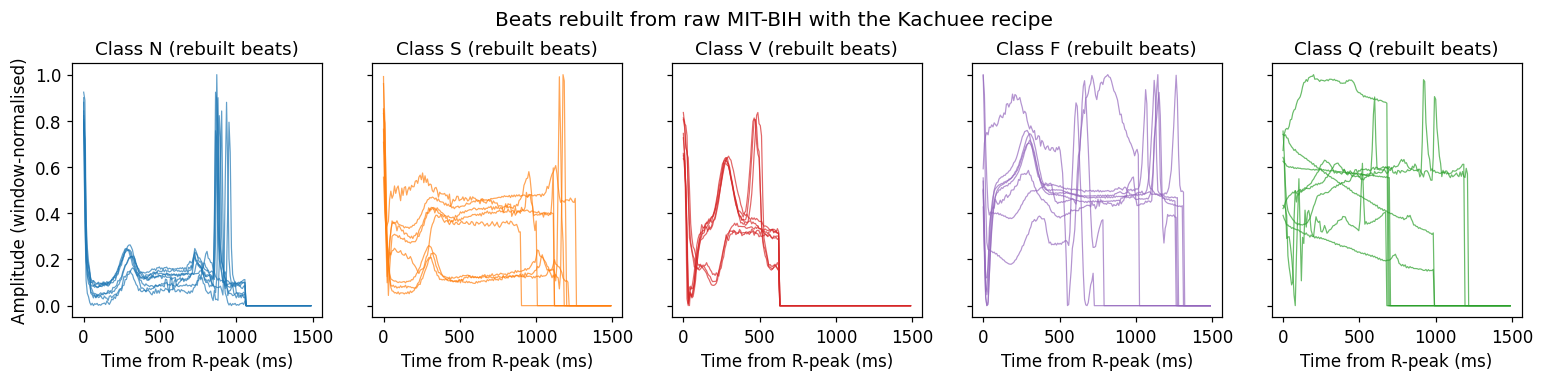

In [4]:
def write_synthetic_mitdb(d, seconds):
    """Synthetic WFDB records (for testing the pipeline only). Patient-specific morphology makes inter-patient harder."""
    d.mkdir(parents=True, exist_ok=True); rng = np.random.default_rng(7)
    sym_for = {0: "N", 1: "A", 2: "V", 3: "F", 4: "Q"}
    for rid in DS1 + DS2:
        hr = rng.uniform(55, 105); wscale = rng.uniform(.8, 1.3); tscale = rng.uniform(.6, 1.4)
        mix = rng.dirichlet(np.array([.75, .07, .1, .03, .05]) * 10 + .05)
        n = seconds * FS_RAW; t = np.arange(n); x = np.zeros(n); samples, symbols = [], []
        pos = int(.5 * FS_RAW)
        while pos < n - FS_RAW:
            c = rng.choice(5, p=mix); rr = 60 / hr * FS_RAW * rng.uniform(.95, 1.05)
            if c in (1, 2): pos = int(pos - .25 * rr)   # premature
            w = {0: 7, 1: 7, 2: 18, 3: 12, 4: 9}[c] * wscale; ta = {0: .3, 1: .28, 2: -.35, 3: .1, 4: .25}[c] * tscale
            seg = slice(max(pos - 150, 0), min(pos + 300, n)); tt = t[seg] - pos
            x[seg] += np.exp(-.5 * (tt / w) ** 2) - .2 * np.exp(-.5 * ((tt - 2.5 * w) / w) ** 2) + ta * np.exp(-.5 * ((tt - .3 * rr) / (.06 * rr)) ** 2)
            if c != 1: x[seg] += .1 * np.exp(-.5 * ((tt + .2 * FS_RAW) / 10) ** 2)
            if c == 4: x[pos:pos + 3] += .5
            samples.append(pos); symbols.append(sym_for[c]); pos = int(pos + rr * (1.3 if c == 2 else 1.0))
        x += .03 * rng.standard_normal(n) + .1 * np.sin(2 * np.pi * t / (3 * FS_RAW))
        sig = np.stack([x, .5 * x + .02 * rng.standard_normal(n)], 1)
        wfdb.wrsamp(str(rid), fs=FS_RAW, units=["mV", "mV"], sig_name=["MLII", "V5"], p_signal=sig, fmt=["212", "212"], write_dir=str(d))
        wfdb.wrann(str(rid), "atr", np.array(samples), symbol=symbols, write_dir=str(d))
    return d

def find_mitdb():
    if USE_SYNTHETIC: return write_synthetic_mitdb(Path("synthetic_mitdb"), 120 if FAST_MODE else 600)
    for h in DATA_DIR_HINTS:
        if h and Path(h).exists():
            hit = next(Path(h).rglob("100.hea"), None)
            if hit: return hit.parent
    if Path("/content").exists() and not Path("/content/drive").exists():
        try:
            from google.colab import drive; drive.mount("/content/drive")
            for h in DATA_DIR_HINTS:
                hit = next(Path(h).rglob("100.hea"), None) if h and Path(h).exists() else None
                if hit: return hit.parent
        except Exception as e: print("Drive mount skipped:", e)
    print("Downloading MIT-BIH from PhysioNet (~100 MB) ..."); wfdb.dl_database("mitdb", dl_dir="mitdb"); return Path("mitdb")

def build_record(d, rid):
    rec = wfdb.rdrecord(str(d / str(rid))); ann = wfdb.rdann(str(d / str(rid)), "atr")
    ch = rec.sig_name.index("MLII") if "MLII" in rec.sig_name else 0
    x = sps.resample_poly(rec.p_signal[:, ch], 25, 72)                       # 360 -> 125 Hz
    sym = np.array(ann.symbol); ok = np.isin(sym, list(AAMI))
    r = np.round(ann.sample[ok] * FS / FS_RAW).astype(int); lab = np.array([AAMI[s] for s in sym[ok]])
    for i in range(len(r)):                                                   # snap to local max (+-3 samples)
        lo, hi = max(r[i] - 3, 0), min(r[i] + 4, len(x)); r[i] = lo + int(np.argmax(x[lo:hi]))
    X, Y, W = [], [], []
    for w0 in range(0, len(x) - WIN + 1, WIN):
        m = (r >= w0) & (r < w0 + WIN); rr = r[m]
        if len(rr) < 2: continue
        Lc = int(min(round(1.2 * np.median(np.diff(rr))), SIG_LEN)); seg = x[w0:w0 + WIN]; lo, hi = seg.min(), seg.max()
        for rp, lb in zip(rr, lab[m]):
            crop = x[rp:rp + Lc]
            if len(crop) < Lc: continue
            b = np.zeros(SIG_LEN, np.float32); b[:Lc] = np.clip((crop - lo) / (hi - lo + 1e-8), 1e-4, 1); X.append(b); Y.append(lb); W.append(w0 // WIN)
    return np.array(X), np.array(Y), np.array(W)

t0 = time.time(); MITDB = find_mitdb(); print("Records from:", MITDB)
parts = [(rid,) + build_record(MITDB, rid) for rid in DS1 + DS2]
X_all = np.concatenate([p[1] for p in parts]); y_all = np.concatenate([p[2] for p in parts])
rec_all = np.concatenate([np.full(len(p[2]), p[0]) for p in parts])
win_all = np.concatenate([p[0] * 10_000 + p[3] for p in parts])               # globally unique window id
is_ds1 = np.isin(rec_all, DS1)
counts = pd.DataFrame({"DS1": np.bincount(y_all[is_ds1], minlength=5), "DS2": np.bincount(y_all[~is_ds1], minlength=5)}, index=CLASSES)
print(counts, f"\n{len(y_all)} beats built in {time.time() - t0:.0f}s")
RESULTS["data"] = dict(counts=counts.to_dict(), n_beats=int(len(y_all)), source=str(MITDB))

def valid_len(X):
    X = np.atleast_2d(X); nz = X != 0; return np.where(nz.any(1), SIG_LEN - np.argmax(nz[:, ::-1], 1), 0)

# ---- the two splits ----
idx_all = np.arange(len(y_all))
tr_i, te_i = train_test_split(idx_all, test_size=.2, stratify=y_all, random_state=0)
tr_i, va_i = train_test_split(tr_i, test_size=.1, stratify=y_all[tr_i], random_state=0)
ds1, ds2 = idx_all[is_ds1], idx_all[~is_ds1]
strat = lambda ix: y_all[ix] if np.bincount(y_all[ix]).min() >= 2 else None
tr_x, va_x = train_test_split(ds1, test_size=.1, stratify=strat(ds1), random_state=0)
SPLIT = {"intra": dict(tr=tr_i, va=va_i, te=te_i), "inter": dict(tr=tr_x, va=va_x, te=ds2)}
POOL = np.intersect1d(te_i, ds2)                                              # unseen by both models
print({a: {k: len(v) for k, v in s.items()} for a, s in SPLIT.items()}, "| evaluation pool:", len(POOL), np.bincount(y_all[POOL], minlength=5))

fig, axes = plt.subplots(1, 5, figsize=(17, 3), sharey=True)
for c, ax in enumerate(axes):
    for i in np.where(y_all == c)[0][:8]: ax.plot(np.arange(SIG_LEN) * 8, X_all[i], lw=.8, color=CCOL[CLASSES[c]], alpha=.7)
    ax.set_title(f"Class {CLASSES[c]} (rebuilt beats)"); ax.set_xlabel("Time from R-peak (ms)")
axes[0].set_ylabel("Amplitude (window-normalised)"); fig.suptitle("Beats rebuilt from raw MIT-BIH with the Kachuee recipe", y=1.04); savefig(fig, "00_rebuilt_beats")
save_results()

## Model (fixed: Kachuee ResNet) and training, 3 seeds × 2 arms

  [intra seed=0] epochs=40 val macro-F1=0.6834
  [intra seed=1] epochs=40 val macro-F1=0.6959
  [intra seed=2] epochs=40 val macro-F1=0.6979
intra: own-test macro-F1 0.7114 ± 0.0227 | recall {'N': 0.9782390917186109, 'S': 0.8921036769138034, 'V': 0.968787228973076, 'F': 0.8708333333333332, 'Q': 0.1111111111111111}
  [inter seed=0] epochs=13 val macro-F1=0.5905
  [inter seed=1] epochs=40 val macro-F1=0.7063
  [inter seed=2] epochs=40 val macro-F1=0.6889
inter: own-test macro-F1 0.3022 ± 0.0131 | recall {'N': 0.7579906605612731, 'S': 0.0812875068194217, 'V': 0.8594252515821142, 'F': 0.23281786941580754, 'Q': 0.19047619047619047}
training done in 489s


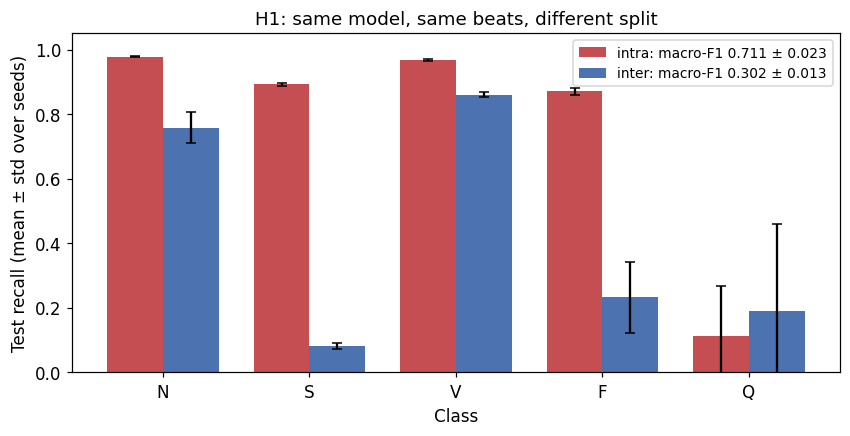

In [5]:
class ResBlock(nn.Module):
    def __init__(s, c=32):
        super().__init__(); s.c1 = nn.Conv1d(c, c, 5, padding=2); s.c2 = nn.Conv1d(c, c, 5, padding=2); s.pool = nn.MaxPool1d(5, 2)
    def forward(s, x): s.pre = F.relu(s.c2(F.relu(s.c1(x))) + x); return s.pool(s.pre)
class KachueeResNet(nn.Module):
    def __init__(s, n=5):
        super().__init__(); s.conv0 = nn.Conv1d(1, 32, 5, padding=2); s.blocks = nn.ModuleList([ResBlock() for _ in range(5)])
        s.fc1 = nn.Linear(64, 32); s.fc2 = nn.Linear(32, 32); s.out = nn.Linear(32, n)
    def forward(s, x, keep_fmap=False):
        if x.dim() == 2: x = x[:, None]
        h = s.conv0(x)
        for b in s.blocks: h = b(h)
        if keep_fmap: s.fmap = s.blocks[-1].pre
        return s.out(F.relu(s.fc2(F.relu(s.fc1(h.flatten(1))))))

def predict_proba(m, X, bs=4096):
    m.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs): out.append(F.softmax(m(torch.as_tensor(X[i:i + bs], device=DEVICE)), 1).cpu())
    return torch.cat(out).numpy()
def metrics(y, p):
    yp = p.argmax(1) if p.ndim == 2 else p
    return dict(macro_f1=float(f1_score(y, yp, average="macro", labels=range(5), zero_division=0)), accuracy=float(accuracy_score(y, yp)),
                recall={c: float(r) for c, r in zip(CLASSES, recall_score(y, yp, average=None, labels=range(5), zero_division=0))})
def train_model(Xtr, ytr, Xva, yva, seed, tag):
    set_seed(seed); m = KachueeResNet().to(DEVICE)
    cnt = np.bincount(ytr, minlength=5).astype(float); w = cnt.sum() / (5 * np.maximum(cnt, 1))
    lossf = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.Adam(m.parameters(), 1e-3); sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "max", .5, 3)
    Xt, yt = torch.as_tensor(Xtr), torch.as_tensor(ytr); g = torch.Generator().manual_seed(seed); best, state, bad = -1, None, 0
    for ep in range(EPOCHS):
        m.train(); perm = torch.randperm(len(Xt), generator=g)
        for i in range(0, len(perm), BATCH):
            j = perm[i:i + BATCH]; opt.zero_grad(); lossf(m(Xt[j].to(DEVICE)), yt[j].to(DEVICE)).backward(); opt.step()
        f1 = metrics(yva, predict_proba(m, Xva))["macro_f1"]; sch.step(f1)
        if f1 > best: best, state, bad = f1, {k: v.detach().clone() for k, v in m.state_dict().items()}, 0
        else: bad += 1
        if bad >= PATIENCE: break
    m.load_state_dict(state); m.eval(); print(f"  [{tag} seed={seed}] epochs={ep + 1} val macro-F1={best:.4f}"); return m

t0 = time.time(); MODELS, PERF = {a: {} for a in ARMS}, {}
for a in ARMS:
    S = SPLIT[a]
    for s in SEEDS: MODELS[a][s] = train_model(X_all[S["tr"]], y_all[S["tr"]], X_all[S["va"]], y_all[S["va"]], s, a)
    own = {s: metrics(y_all[S["te"]], predict_proba(MODELS[a][s], X_all[S["te"]])) for s in SEEDS}
    pool = {s: metrics(y_all[POOL], predict_proba(MODELS[a][s], X_all[POOL])) for s in SEEDS}
    f = [own[s]["macro_f1"] for s in SEEDS]
    PERF[a] = dict(own_test=own, pool=pool, macro_f1_mean=float(np.mean(f)), macro_f1_std=float(np.std(f)),
                   macro_f1_ci_seed0=boot_f1(y_all[S["te"]], predict_proba(MODELS[a][SEEDS[0]], X_all[S["te"]]).argmax(1)),
                   recall_mean={c: float(np.mean([own[s]["recall"][c] for s in SEEDS])) for c in CLASSES},
                   recall_std={c: float(np.std([own[s]["recall"][c] for s in SEEDS])) for c in CLASSES})
    print(f"{a}: own-test macro-F1 {PERF[a]['macro_f1_mean']:.4f} ± {PERF[a]['macro_f1_std']:.4f} | recall {PERF[a]['recall_mean']}")
RESULTS["performance"] = PERF; save_results(); print(f"training done in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(9, 4)); w = .38
for k, a in enumerate(ARMS):
    ax.bar(np.arange(5) + (k - .5) * w, [PERF[a]["recall_mean"][c] for c in CLASSES], w, yerr=[PERF[a]["recall_std"][c] for c in CLASSES],
           capsize=3, color=ACOL[a], label=f"{a}: macro-F1 {PERF[a]['macro_f1_mean']:.3f} ± {PERF[a]['macro_f1_std']:.3f}")
ax.set_xticks(range(5), CLASSES); ax.set_xlabel("Class"); ax.set_ylabel("Test recall (mean ± std over seeds)"); ax.set_ylim(0, 1.05)
ax.set_title("H1: same model, same beats, different split"); ax.legend(); savefig(fig, "01_performance_intra_vs_inter")

## H2 · Leakage diagnostics (direct, using record and window IDs)
For each test beat, find its nearest training beat (Euclidean distance) and check whether it shares the **record**, the **10 s window**, or the **exact valid length L**. Paper 1 could only use L, as a proxy. Here we can check whether that proxy tracks true window sharing.

intra {'nn_f1': 0.715, 'same_record': 0.918, 'same_window': 0.154, 'same_L': 0.624, 'same_L_chance': 0.014, 'L_only_f1': 0.224, 'same_L_given_same_window': 1.0}
inter {'nn_f1': 0.36, 'same_record': 0.0, 'same_window': 0.0, 'same_L': 0.365, 'same_L_chance': 0.013, 'L_only_f1': 0.155, 'same_L_given_same_window': nan}


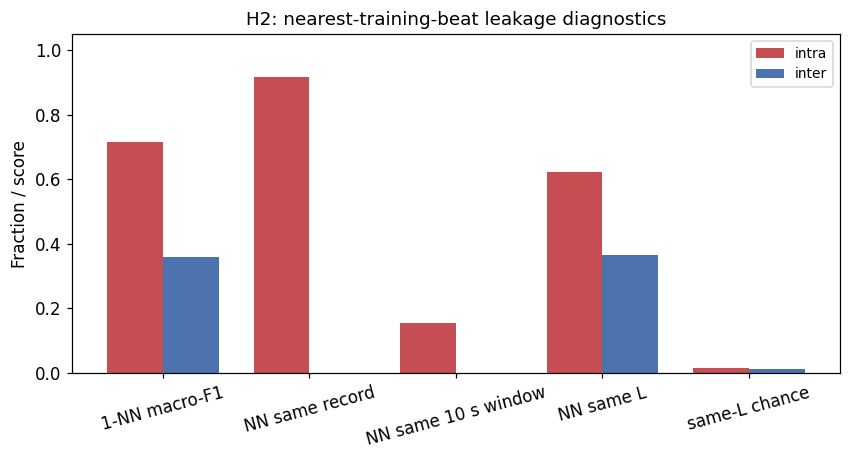

In [6]:
L_all = valid_len(X_all); LEAK = {}
for a in ARMS:
    S = SPLIT[a]; Xtr_t = torch.as_tensor(X_all[S["tr"]], device=DEVICE); nn_j = []
    for i in range(0, len(S["te"]), 512):
        nn_j.append(torch.cdist(torch.as_tensor(X_all[S["te"][i:i + 512]], device=DEVICE), Xtr_t).argmin(1).cpu())
    nn_g = S["tr"][torch.cat(nn_j).numpy()]; te = S["te"]
    pL = np.bincount(L_all[S["tr"]], minlength=SIG_LEN + 1) / len(S["tr"])
    hgb = HistGradientBoostingClassifier(max_iter=150, class_weight="balanced", random_state=0).fit(L_all[S["tr"]][:, None], y_all[S["tr"]])
    LEAK[a] = dict(nn_f1=metrics(y_all[te], y_all[nn_g])["macro_f1"], same_record=float((rec_all[nn_g] == rec_all[te]).mean()),
                   same_window=float((win_all[nn_g] == win_all[te]).mean()), same_L=float((L_all[nn_g] == L_all[te]).mean()),
                   same_L_chance=float(pL[L_all[te]].mean()), L_only_f1=metrics(y_all[te], hgb.predict(L_all[te][:, None]))["macro_f1"],
                   same_L_given_same_window=float((L_all[nn_g] == L_all[te])[win_all[nn_g] == win_all[te]].mean()) if (win_all[nn_g] == win_all[te]).any() else np.nan)
    print(a, {k: round(v, 3) for k, v in LEAK[a].items()})
RESULTS["leakage"] = LEAK; save_results()
fig, ax = plt.subplots(figsize=(9, 4)); keys = ["nn_f1", "same_record", "same_window", "same_L", "same_L_chance"]
labs = ["1-NN macro-F1", "NN same record", "NN same 10 s window", "NN same L", "same-L chance"]
for k, a in enumerate(ARMS): ax.bar(np.arange(len(keys)) + (k - .5) * .38, [LEAK[a][q] for q in keys], .38, color=ACOL[a], label=a)
ax.set_xticks(range(len(keys)), labs, rotation=15); ax.set_ylabel("Fraction / score"); ax.set_ylim(0, 1.05)
ax.set_title("H2: nearest-training-beat leakage diagnostics"); ax.legend(); savefig(fig, "02_leakage_diagnostics")

## XAI machinery (identical to paper 1)

In [7]:
METHODS = ["Saliency", "SmoothGrad", "IntGrad", "GradCAM", "Occlusion", "Shapley", "Random"]; SIGNED = {"IntGrad", "Occlusion", "Shapley"}
_trapz = getattr(np, "trapezoid", None) or np.trapz
def _t(a): return torch.as_tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)
def grad_logit(m, x, tgt):
    x = x.clone().requires_grad_(True); g, = torch.autograd.grad(m(x).gather(1, tgt[:, None]).sum(), x); return g
def prob_batched(m, X, tgt, bs=8192):
    with torch.no_grad(): return torch.cat([F.softmax(m(X[i:i + bs]), 1).gather(1, tgt[i:i + bs, None])[:, 0] for i in range(0, len(X), bs)])
def interp_fill(x, keep):
    out = x.copy(); g = np.arange(x.shape[1])
    for i in range(len(x)):
        k = keep[i]
        if not k.all(): out[i] = np.interp(g, g[k], x[i, k]) if k.any() else np.median(x[i])
    return out

def attribute(m, X, y, method, rng, mean_beat):
    m.eval(); x = _t(X); tgt = torch.as_tensor(y, device=DEVICE); n = len(X)
    if method == "Random": return rng.random(X.shape)
    if method == "Saliency": return grad_logit(m, x, tgt).abs().cpu().numpy()
    if method == "SmoothGrad":
        acc = torch.zeros_like(x)
        for _ in range(SG_N): acc += grad_logit(m, x + SG_SIGMA * torch.randn_like(x), tgt).abs()
        return (acc / SG_N).cpu().numpy()
    if method == "IntGrad":
        base = _t(mean_beat)[None].expand_as(x); acc = torch.zeros_like(x)
        for a in (torch.arange(IG_STEPS, device=DEVICE) + .5) / IG_STEPS: acc += grad_logit(m, base + a * (x - base), tgt)
        return ((x - base) * acc / IG_STEPS).cpu().numpy()
    if method == "GradCAM":
        xx = x.clone().requires_grad_(True); lg = m(xx, keep_fmap=True); g, = torch.autograd.grad(lg.gather(1, tgt[:, None]).sum(), m.fmap)
        cam = F.relu((g.mean(2, keepdim=True) * m.fmap).sum(1, keepdim=True))
        return F.interpolate(cam, size=SIG_LEN, mode="linear", align_corners=False)[:, 0].detach().cpu().numpy()
    if method == "Occlusion":
        starts = list(range(0, SIG_LEN - OCC_W + 1, OCC_S)) + [SIG_LEN - OCC_W]
        p0 = prob_batched(m, x, tgt); att = torch.zeros_like(x); cnt = torch.zeros(SIG_LEN, device=DEVICE); w = torch.linspace(0, 1, OCC_W + 2, device=DEVICE)[1:-1]
        for s0 in sorted(set(starts)):
            xo = x.clone(); lo, hi = max(s0 - 1, 0), min(s0 + OCC_W, SIG_LEN - 1)
            xo[:, s0:s0 + OCC_W] = x[:, lo:lo + 1] * (1 - w) + x[:, hi:hi + 1] * w
            att[:, s0:s0 + OCC_W] += (p0 - prob_batched(m, xo, tgt))[:, None]; cnt[s0:s0 + OCC_W] += 1
        return (att / cnt).cpu().numpy()
    if method == "Shapley":
        nseg = math.ceil(SIG_LEN / SHAP_SEG); seg_id = torch.arange(SIG_LEN, device=DEVICE) // SHAP_SEG; base = _t(mean_beat); phi = torch.zeros(n, nseg, device=DEVICE)
        for _ in range(SHAP_PERMS):
            perm = torch.as_tensor(np.stack([rng.permutation(nseg) for _ in range(n)]), device=DEVICE); rank = torch.argsort(perm, 1)
            mask = (rank[:, None, :] < torch.arange(nseg + 1, device=DEVICE)[None, :, None])[:, :, seg_id].float()
            v = prob_batched(m, (mask * x[:, None] + (1 - mask) * base).reshape(-1, SIG_LEN), tgt.repeat_interleave(nseg + 1)).reshape(n, nseg + 1)
            phi.scatter_add_(1, perm, v[:, 1:] - v[:, :-1])
        return (phi / SHAP_PERMS)[:, seg_id].cpu().numpy() / SHAP_SEG
    raise ValueError(method)

def order_scores(a, method, rng): return (a if method in SIGNED else np.abs(a)) + 1e-9 * rng.random(a.shape)
def del_ins_auc(m, X, y, a, baseline, counter_mean):
    order = np.argsort(-a, 1); fr = np.linspace(0, 1, DEL_STEPS + 1); tgt = torch.as_tensor(y, device=DEVICE); B = counter_mean[y]; D, I = [], []
    for f in fr:
        k = int(round(f * SIG_LEN)); top = np.zeros_like(X, bool)
        if k: np.put_along_axis(top, order[:, :k], True, 1)
        if baseline == "interp": xd = interp_fill(X, ~top); xi = interp_fill(X, top) if k else np.repeat(np.median(X, 1, keepdims=True), SIG_LEN, 1)
        else: xd = np.where(top, B, X); xi = np.where(top, X, B)
        D.append(prob_batched(m, _t(xd), tgt).cpu().numpy()); I.append(prob_batched(m, _t(xi), tgt).cpu().numpy())
    D, I = np.stack(D, 1), np.stack(I, 1); return _trapz(D, fr, axis=1), _trapz(I, fr, axis=1)
def randomised_full(m, seed):
    r = KachueeResNet().to(DEVICE); r.load_state_dict(m.state_dict()); torch.manual_seed(10_000 + seed)
    for sub in r.modules():
        if hasattr(sub, "reset_parameters"): sub.reset_parameters()
    return r.eval()
def topk_jaccard(a, b, k):
    ia, ib = np.argsort(-a, 1)[:, :k], np.argsort(-b, 1)[:, :k]; return np.array([len(set(p) & set(q)) / len(set(p) | set(q)) for p, q in zip(ia, ib)])
def rowwise_spearman(a, b): return np.array([spearmanr(p, q)[0] for p, q in zip(a, b)])
ARM_STATS = {}
for a in ARMS:
    tr = SPLIT[a]["tr"]; cm = np.stack([X_all[tr][y_all[tr] == c].mean(0) for c in range(5)])
    ARM_STATS[a] = dict(mean_beat=X_all[tr].mean(0), counter_mean=np.stack([cm[[k for k in range(5) if k != c]].mean(0) for c in range(5)]))

## H3 · Do explanations change when leakage is removed?
Use beats from the evaluation pool that **every model in both arms** classifies correctly. For each method, compute per-beat Spearman ρ of |attribution| between model pairs:
* **within-intra** and **within-inter**: different seeds of the same arm. This is the noise floor.
* **cross**: an intra model vs an inter model.

The explanation shift is within-arm agreement minus cross agreement. Positive, with a CI excluding 0, means leakage changed what the model attends to beyond seed noise.

Beats correct in both arms, per class: [100   9 100   2   0]
            within_intra  within_inter  cross  shift  \
method                                                 
Saliency           0.549         0.537  0.522  0.021   
SmoothGrad         0.724         0.775  0.695  0.055   
IntGrad            0.744         0.739  0.715  0.026   
GradCAM            0.408         0.482  0.416  0.029   
Occlusion          0.751         0.838  0.733  0.064   
Shapley            0.628         0.694  0.630  0.031   
Random             0.002         0.002  0.001  0.001   

                                                 shift_ci  
method                                                     
Saliency      (0.015851256782665604, 0.02547250802257514)  
SmoothGrad     (0.04657223363342071, 0.06442848909080638)  
IntGrad       (0.02331539722937304, 0.029499841665912564)  
GradCAM      (0.012761066000388482, 0.045570919706465804)  
Occlusion      (0.05087087769048532, 0.07715599663703739)  
Shapley      (

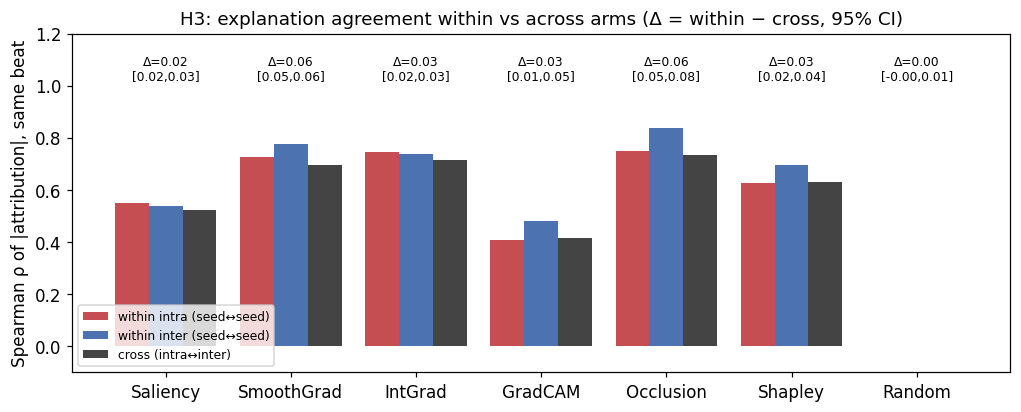

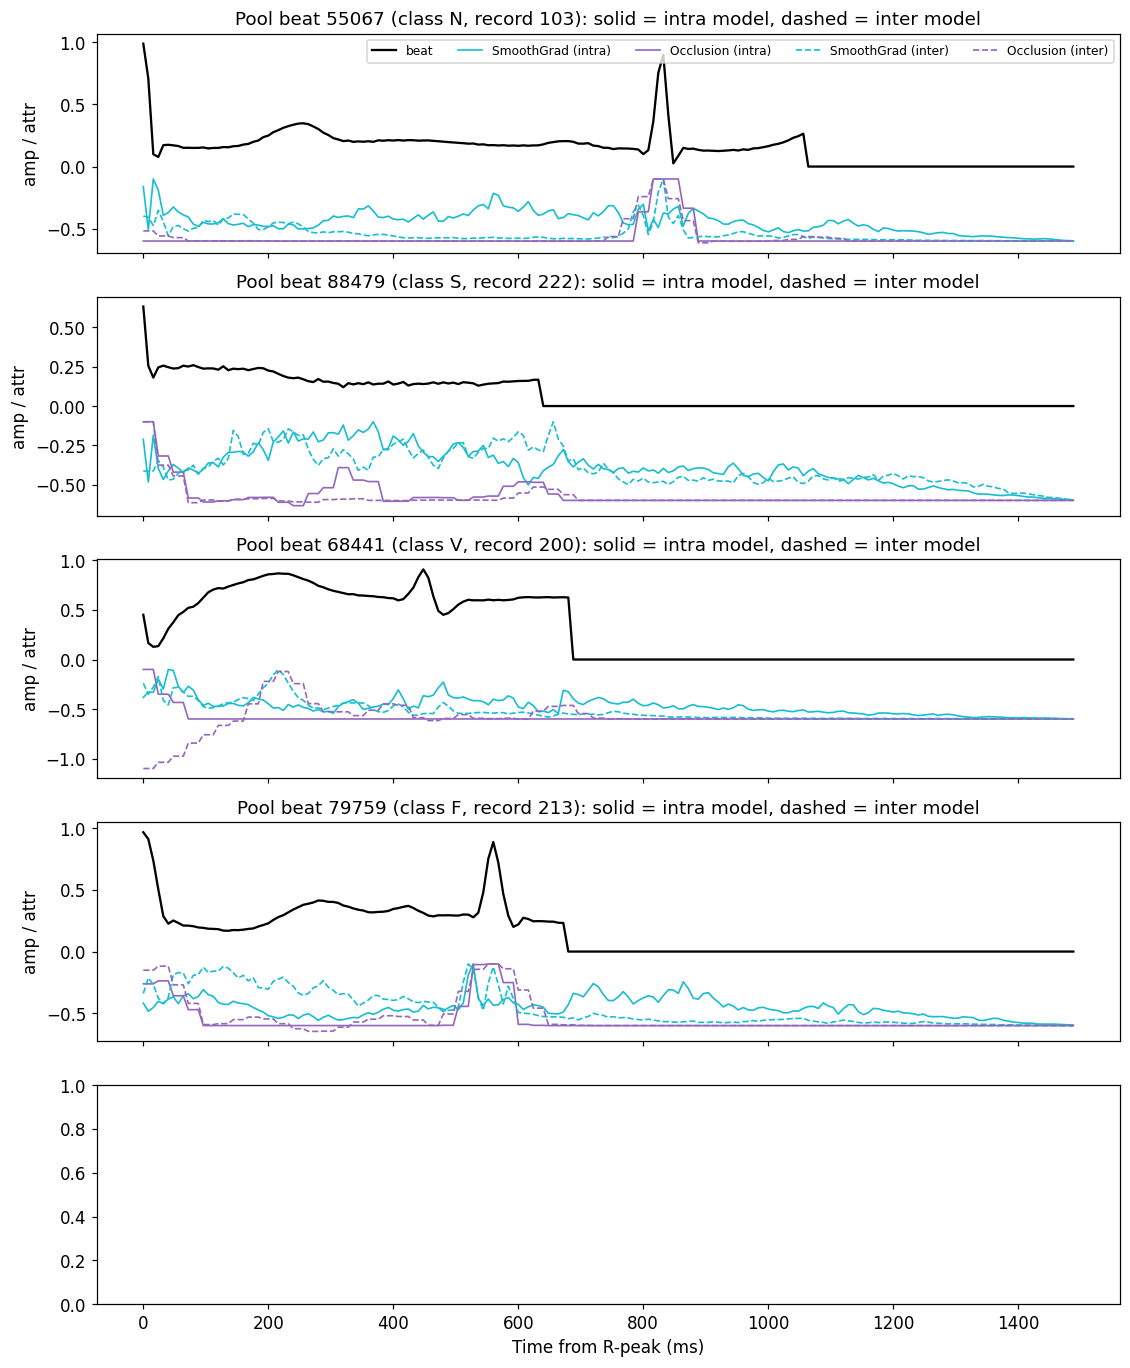

H3 done in 27s


In [8]:
t0 = time.time(); K = int(TOPK_FRAC * SIG_LEN)
POOL_P = {a: {s: predict_proba(MODELS[a][s], X_all[POOL]) for s in SEEDS} for a in ARMS}
ok_both = np.all([POOL_P[a][s].argmax(1) == y_all[POOL] for a in ARMS for s in SEEDS], 0)
common = np.concatenate([np.random.default_rng(c).permutation(POOL[ok_both & (y_all[POOL] == c)])[:N_PER_CLASS] for c in range(5)])
Xc, yc = X_all[common], y_all[common]; print("Beats correct in both arms, per class:", np.bincount(yc, minlength=5))
ATT = {(a, s, mth): attribute(MODELS[a][s], Xc, yc, mth, np.random.default_rng(s + 1000 * ARMS.index(a)), ARM_STATS[a]["mean_beat"]) for a in ARMS for s in SEEDS for mth in METHODS}
rows = []
for mth in METHODS:
    pairs = {"within_intra": list(itertools.combinations([("intra", s) for s in SEEDS], 2)),
             "within_inter": list(itertools.combinations([("inter", s) for s in SEEDS], 2)),
             "cross": [(("intra", s1), ("inter", s2)) for s1 in SEEDS for s2 in SEEDS]}
    per = {}
    for kind, pl in pairs.items():
        per[kind] = np.nanmean([rowwise_spearman(np.abs(ATT[(p[0], p[1], mth)]), np.abs(ATT[(q[0], q[1], mth)])) for p, q in pl], 0)
        per[kind + "_topk"] = np.mean([topk_jaccard(np.abs(ATT[(p[0], p[1], mth)]), np.abs(ATT[(q[0], q[1], mth)]), K) for p, q in pl], 0)
    for j in range(len(common)):
        rows.append(dict(method=mth, cls=CLASSES[yc[j]], beat=int(common[j]), **{k: v[j] for k, v in per.items()}))
SH = pd.DataFrame(rows); SH["within"] = (SH.within_intra + SH.within_inter) / 2; SH["shift"] = SH.within - SH.cross
SH.to_csv(OUT / "explanation_shift_per_beat.csv", index=False)
shift_sum = SH.groupby("method").agg(within_intra=("within_intra", "mean"), within_inter=("within_inter", "mean"), cross=("cross", "mean"), shift=("shift", "mean")).reindex(METHODS)
shift_sum["shift_ci"] = [boot_ci(SH[SH.method == m_]["shift"].values) for m_ in METHODS]
shift_cls = SH.groupby(["method", "cls"])["shift"].mean().unstack().reindex(METHODS)
print(shift_sum.round(3)); print("Shift by class:\n", shift_cls.round(3))
RESULTS["explanation_shift"] = dict(summary=shift_sum.reset_index().to_dict("records"), by_class=shift_cls.to_dict(), n_beats=np.bincount(yc, minlength=5).tolist())
save_results()
fig, ax = plt.subplots(figsize=(11, 4)); xm = np.arange(len(METHODS)); w = .27
for k, (col, lab, cc) in enumerate([("within_intra", "within intra (seed↔seed)", ACOL["intra"]), ("within_inter", "within inter (seed↔seed)", ACOL["inter"]), ("cross", "cross (intra↔inter)", "#444")]):
    ax.bar(xm + (k - 1) * w, shift_sum[col], w, label=lab, color=cc)
for i, m_ in enumerate(METHODS):
    lo, hi = shift_sum.loc[m_, "shift_ci"]; ax.text(i, 1.02, f"Δ={shift_sum.loc[m_, 'shift']:.2f}\n[{lo:.2f},{hi:.2f}]", ha="center", fontsize=8)
ax.set_xticks(xm, METHODS); ax.set_ylim(-.1, 1.2); ax.set_ylabel("Spearman ρ of |attribution|, same beat")
ax.set_title("H3: explanation agreement within vs across arms (Δ = within − cross, 95% CI)"); ax.legend(loc="lower left", fontsize=8); savefig(fig, "03_explanation_shift")
fig, axes = plt.subplots(5, 1, figsize=(12, 15), sharex=True); tms = np.arange(SIG_LEN) * 8
for c in range(5):
    jj = np.where(yc == c)[0]
    if not len(jj): continue
    j = jj[0]; ax = axes[c]; ax.plot(tms, Xc[j], c="k", lw=1.5, label="beat")
    for a, ls in [("intra", "-"), ("inter", "--")]:
        for mth in ["SmoothGrad", "Occlusion"]:
            v = np.abs(ATT[(a, SEEDS[0], mth)][j]) if mth not in SIGNED else ATT[(a, SEEDS[0], mth)][j]
            ax.plot(tms, v / (np.abs(v).max() + 1e-12) * .5 - .6, ls, c=MCOL[mth], lw=1.1, label=f"{mth} ({a})")
    ax.set_title(f"Pool beat {common[j]} (class {CLASSES[c]}, record {rec_all[common[j]]}): solid = intra model, dashed = inter model"); ax.set_ylabel("amp / attr")
axes[0].legend(ncol=5, fontsize=8); axes[-1].set_xlabel("Time from R-peak (ms)"); savefig(fig, "04_example_attributions_both_arms")
print(f"H3 done in {time.time() - t0:.0f}s")

## H4 · Does leakage change which explanation method looks faithful?
Each arm is scored on pool beats that its own models classify correctly (all seeds). The metrics are deletion/insertion AUC with the interp and counter-class-mean baselines, Spearman at full model randomisation (sanity), and stability under small noise.

  intra: [100 100 100  66   0] beats/class (38s)
  inter: [100   9 100   2   0] beats/class (62s)
  arm     method  del_interp  ins_interp  del_cmean  ins_cmean  sanity_spearman  stab_spearman  faith_rank
inter    GradCAM       0.443       0.782      0.466      0.762            0.253          0.978        5.00
inter    IntGrad       0.658       0.864      0.409      0.866            0.610          0.932        2.75
inter  Occlusion       0.468       0.856      0.448      0.799            0.850          0.934        3.75
inter     Random       0.800       0.809      0.679      0.693           -0.005         -0.003        6.75
inter   Saliency       0.519       0.857      0.474      0.806            0.440          0.826        4.25
inter    Shapley       0.442       0.811      0.243      0.895            0.640          0.808        2.00
inter SmoothGrad       0.459       0.844      0.452      0.825            0.442          0.927        3.50
intra    GradCAM       0.416       0.707      

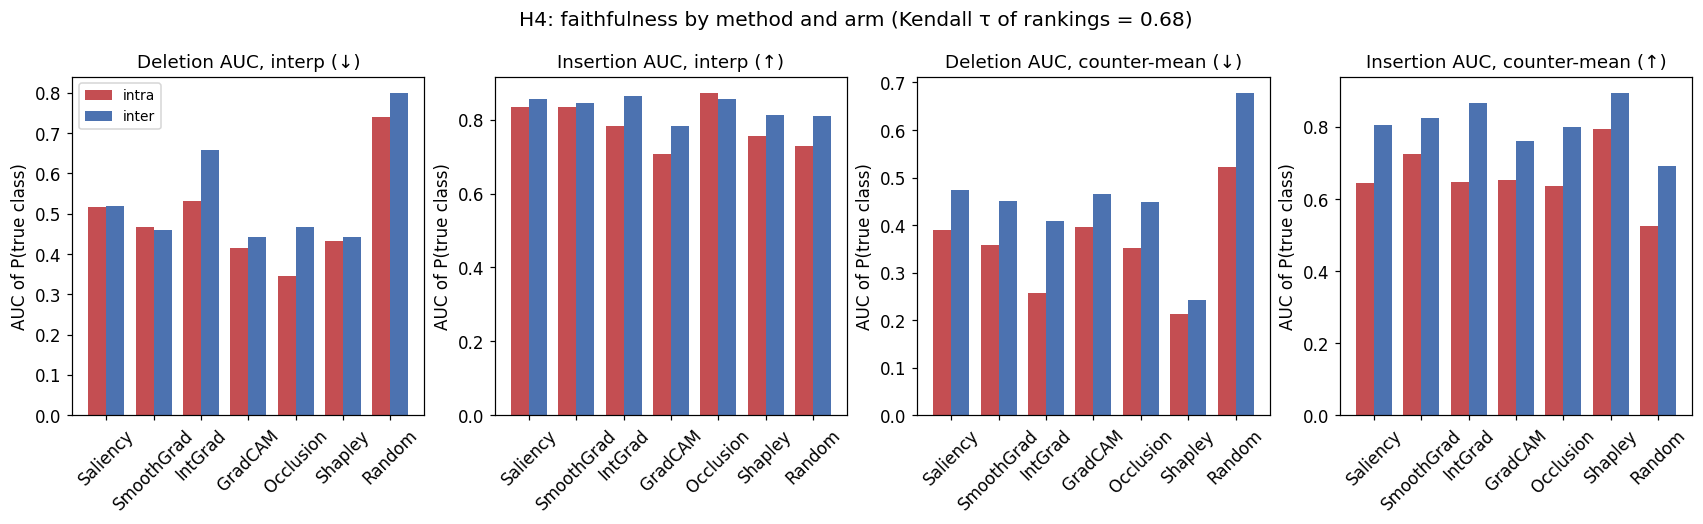

In [9]:
t0 = time.time(); FROWS = []
for a in ARMS:
    ok = np.all([POOL_P[a][s].argmax(1) == y_all[POOL] for s in SEEDS], 0)
    sel = np.concatenate([np.random.default_rng(c).permutation(POOL[ok & (y_all[POOL] == c)])[:N_PER_CLASS] for c in range(5)])
    Xs, ys = X_all[sel], y_all[sel]; st = ARM_STATS[a]
    for s in SEEDS:
        m = MODELS[a][s]; rng = np.random.default_rng(s); mr = randomised_full(m, s)
        Xn = (Xs + STAB_SIGMA * np.random.default_rng(100 + s).standard_normal(Xs.shape) * (Xs != 0)).astype(np.float32); same = predict_proba(m, Xn).argmax(1) == ys
        ss = np.concatenate([np.where(ys == c)[0][:N_SANITY] for c in range(5)])
        for mth in METHODS:
            att = attribute(m, Xs, ys, mth, rng, st["mean_beat"]); sc = order_scores(att, mth, rng)
            di, ii = del_ins_auc(m, Xs, ys, sc, "interp", st["counter_mean"]); dc, ic = del_ins_auc(m, Xs, ys, sc, "cmean", st["counter_mean"])
            stab = rowwise_spearman(np.abs(att), np.abs(attribute(m, Xn, ys, mth, rng, st["mean_beat"])))
            san = np.full(len(sel), np.nan); san[ss] = rowwise_spearman(np.abs(att[ss]), np.abs(attribute(mr, Xs[ss], ys[ss], mth, rng, st["mean_beat"])))
            for j in range(len(sel)):
                FROWS.append(dict(arm=a, seed=s, beat=int(sel[j]), cls=CLASSES[ys[j]], method=mth, del_interp=di[j], ins_interp=ii[j], del_cmean=dc[j], ins_cmean=ic[j],
                                  stab_spearman=stab[j] if same[j] else np.nan, sanity_spearman=san[j]))
    print(f"  {a}: {np.bincount(ys, minlength=5)} beats/class ({time.time() - t0:.0f}s)")
FB = pd.DataFrame(FROWS); FB.to_csv(OUT / "faithfulness_per_beat.csv", index=False)
MET = ["del_interp", "ins_interp", "del_cmean", "ins_cmean", "sanity_spearman", "stab_spearman"]
FS_ = FB.groupby(["arm", "method"])[MET].mean().reset_index()
FS_["faith_rank"] = FS_.groupby("arm").apply(lambda d: (d.del_interp.rank() + (-d.ins_interp).rank() + d.del_cmean.rank() + (-d.ins_cmean).rank()) / 4).reset_index(level=0, drop=True)
FS_.to_csv(OUT / "faithfulness_summary_by_arm.csv", index=False)
ra = FS_[FS_.arm == "intra"].set_index("method").faith_rank.reindex(METHODS); rb = FS_[FS_.arm == "inter"].set_index("method").faith_rank.reindex(METHODS)
tau = kendalltau(ra, rb); print(FS_.round(3).to_string(index=False)); print(f"Kendall tau between arms' faithfulness rankings: {tau.statistic:.3f} (p={tau.pvalue:.3f})")
RESULTS["faithfulness"] = dict(summary=FS_.to_dict("records"), kendall_tau=float(tau.statistic), kendall_p=float(tau.pvalue)); save_results()
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, mt, lab in zip(axes, ["del_interp", "ins_interp", "del_cmean", "ins_cmean"], ["Deletion AUC, interp (↓)", "Insertion AUC, interp (↑)", "Deletion AUC, counter-mean (↓)", "Insertion AUC, counter-mean (↑)"]):
    for k, a in enumerate(ARMS):
        d = FS_[FS_.arm == a].set_index("method").reindex(METHODS); ax.bar(np.arange(len(METHODS)) + (k - .5) * .38, d[mt], .38, color=ACOL[a], label=a)
    ax.set_xticks(range(len(METHODS)), METHODS, rotation=45); ax.set_title(lab); ax.set_ylabel("AUC of P(true class)")
axes[0].legend(); fig.suptitle(f"H4: faithfulness by method and arm (Kendall τ of rankings = {tau.statistic:.2f})", y=1.03); savefig(fig, "05_faithfulness_by_arm")

## H5 · Do the causal concept effects change?
The same signal edits as in paper 1, applied to the **same pool beats** (all beats of the class, not only correctly classified ones) for both arms. P(class) is averaged over seeds. For each beat, the effect = P(edited) − P(unedited); the arm difference is inter − intra, with a paired bootstrap CI.

{
 "N_qrs_stretch_x2.0_dP(V)": {
  "intra": 0.16709618270397186,
  "intra_ci": [
   0.11444298880026145,
   0.2245498695952212
  ],
  "inter": 0.210237517952919,
  "inter_ci": [
   0.15471052956984566,
   0.26704029340674057
  ],
  "diff_inter_minus_intra": 0.043141331523656845,
  "diff_ci": [
   0.0016266878517262756,
   0.08386217686530402
  ],
  "n": 100
 },
 "V_qrs_stretch_x0.6_dP(V)": {
  "intra": -0.10353370755910873,
  "intra_ci": [
   -0.14559465868771077,
   -0.06341784442216158
  ],
  "inter": -0.09560585021972656,
  "inter_ci": [
   -0.12592626740940613,
   -0.06956460093986247
  ],
  "diff_inter_minus_intra": 0.007927839644253254,
  "diff_ci": [
   -0.029117950659245252,
   0.046220019908621894
  ],
  "n": 100
 },
 "N_t_scale_x-1.0_dP(V)": {
  "intra": 0.0053342003375291824,
  "intra_ci": [
   -0.004693285234688647,
   0.019855182383607846
  ],
  "inter": -0.0057413456961512566,
  "inter_ci": [
   -0.03383164742956342,
   0.023941806002174857
  ],
  "diff_inter_minus_intra"

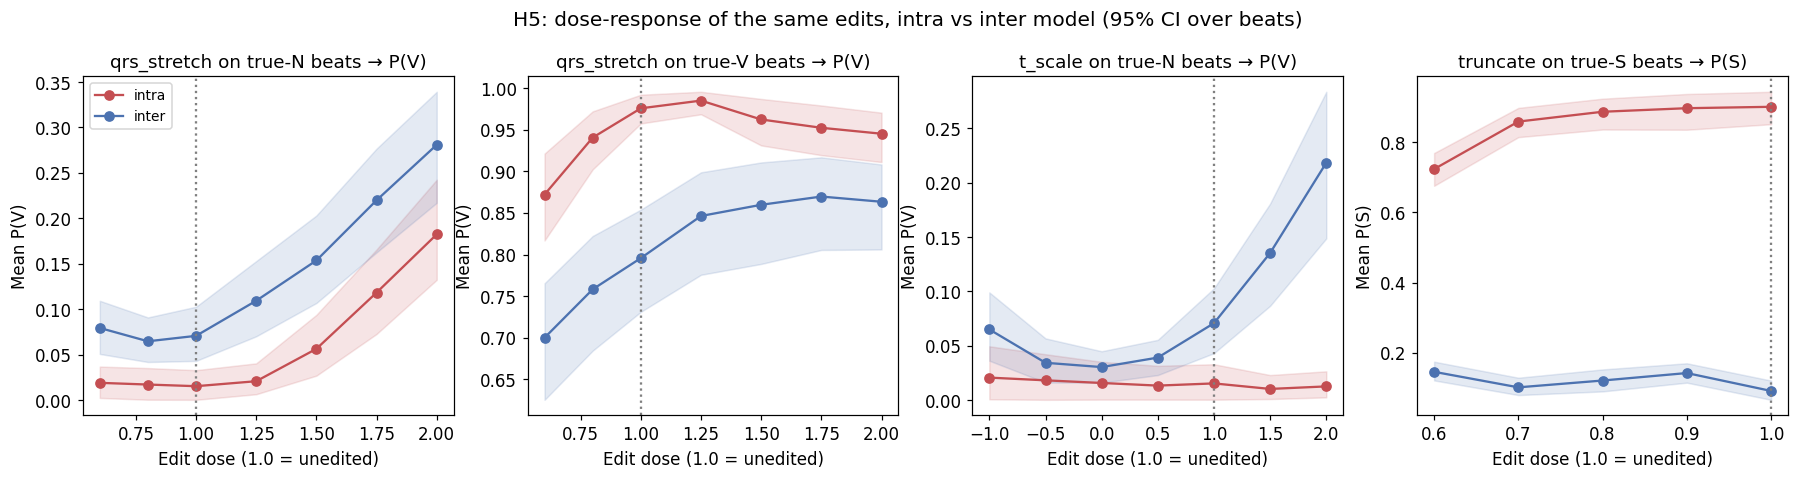

H5 done in 4s


In [10]:
def landmarks(v):
    L = len(v); base = np.median(v); r = v[:3].max() - base; Tm = L / 1.2
    below = np.where(v < base + .5 * r)[0]; qhw = int(below[0]) if len(below) else L - 1
    qend = int(min(qhw + np.argmin(v[qhw:qhw + 15]) + 3, L - 2)) if qhw < L - 1 else L - 2
    lo = min(qend + 2, L - 2); hi = int(max(lo + 3, min(0.6 * Tm, L))); return dict(L=L, base=base, qend=qend, tlo=lo, thi=min(hi, L))
def edit(x, kind, s):
    x = x.copy(); L = int(valid_len(x)[0]); v = x[:L].astype(float); k = landmarks(v)
    if kind == "qrs_stretch":
        q = max(k["qend"], 3); n2 = max(2, int(round(q * s))); v2 = np.r_[np.interp(np.linspace(0, q - 1, n2), np.arange(q), v[:q]), v[q:]]
        v2 = v2[:L] if len(v2) >= L else np.r_[v2, np.full(L - len(v2), v[-1])]
    elif kind == "r_scale":
        q = max(k["qend"], 3); w = np.zeros(L); w[:q] = .5 * (1 + np.cos(np.pi * np.arange(q) / q)); v2 = k["base"] + (v - k["base"]) * (1 + (s - 1) * w)
    elif kind == "t_scale":
        w = np.zeros(L)
        if k["thi"] - k["tlo"] >= 3: w[k["tlo"]:k["thi"]] = np.hanning(k["thi"] - k["tlo"])
        v2 = v + (s - 1) * w * (v - k["base"])
    elif kind == "truncate":
        v2 = v.copy(); v2[int(round(s * L)):] = 0; x[:L] = v2; return x.astype(np.float32)
    x[:L] = np.clip(v2, 1e-4, 1); return x.astype(np.float32)
EDITS = {"qrs_stretch": [.6, .8, 1., 1.25, 1.5, 1.75, 2.], "r_scale": [.4, .6, .8, 1.], "t_scale": [-1., -.5, 0., .5, 1., 1.5, 2.], "truncate": [.6, .7, .8, .9, 1.]}
t0 = time.time(); IROWS = []
for c in range(5):
    cand = np.random.default_rng(50 + c).permutation(POOL[y_all[POOL] == c])[:N_PER_CLASS]
    for kind, doses in EDITS.items():
        for dsg in doses:
            Xe = np.stack([edit(X_all[i], kind, dsg) for i in cand])
            for a in ARMS:
                P = np.mean([predict_proba(MODELS[a][s], Xe) for s in SEEDS], 0)
                for j in range(len(cand)): IROWS.append(dict(arm=a, cls=CLASSES[c], beat=int(cand[j]), edit=kind, dose=dsg, **{f"P_{k}": P[j, q] for q, k in enumerate(CLASSES)}))
DI = pd.DataFrame(IROWS); DI.to_csv(OUT / "interventions_per_beat.csv", index=False)
def effect(arm, cls, kind, dose, tgt):
    d = DI[(DI.arm == arm) & (DI.cls == cls) & (DI.edit == kind)]
    return (d[d.dose == dose].set_index("beat")[f"P_{tgt}"] - d[d.dose == 1.0].set_index("beat")[f"P_{tgt}"]).dropna()
HEAD = [("N", "qrs_stretch", 2.0, "V"), ("V", "qrs_stretch", .6, "V"), ("N", "t_scale", -1.0, "V"), ("N", "truncate", .6, "N"), ("S", "truncate", .6, "S"), ("N", "r_scale", .4, "N")]
H5 = {}
for cls, kind, dose, tgt in HEAD:
    ea, eb = effect("intra", cls, kind, dose, tgt), effect("inter", cls, kind, dose, tgt); diff = (eb - ea).dropna()
    H5[f"{cls}_{kind}_x{dose}_dP({tgt})"] = dict(intra=float(ea.mean()), intra_ci=boot_ci(ea.values), inter=float(eb.mean()), inter_ci=boot_ci(eb.values),
                                               diff_inter_minus_intra=float(diff.mean()), diff_ci=boot_ci(diff.values), n=int(len(diff)))
print(json.dumps(H5, indent=1)); RESULTS["concept_effects"] = H5; save_results()
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (cls, kind, tgt) in zip(axes, [("N", "qrs_stretch", "V"), ("V", "qrs_stretch", "V"), ("N", "t_scale", "V"), ("S", "truncate", "S")]):
    for a in ARMS:
        d = DI[(DI.arm == a) & (DI.cls == cls) & (DI.edit == kind)]; g = d.groupby("dose")[f"P_{tgt}"]; mu = g.mean(); ci = np.array([boot_ci(v.values, n=300) for _, v in g])
        ax.plot(mu.index, mu.values, "o-", c=ACOL[a], label=a); ax.fill_between(mu.index, ci[:, 0], ci[:, 1], color=ACOL[a], alpha=.15)
    ax.axvline(1, c="gray", ls=":"); ax.set_title(f"{kind} on true-{cls} beats → P({tgt})"); ax.set_xlabel("Edit dose (1.0 = unedited)"); ax.set_ylabel(f"Mean P({tgt})")
axes[0].legend(); fig.suptitle("H5: dose-response of the same edits, intra vs inter model (95% CI over beats)", y=1.03); savefig(fig, "06_dose_response_by_arm")
print(f"H5 done in {time.time() - t0:.0f}s")

## Summary (paste this back for interpretation)

In [11]:
summ = {"performance": {a: dict(macro_f1=f"{PERF[a]['macro_f1_mean']:.4f}±{PERF[a]['macro_f1_std']:.4f}", recall={c: round(v, 3) for c, v in PERF[a]["recall_mean"].items()}) for a in ARMS},
        "leakage": {a: {k: round(v, 3) for k, v in LEAK[a].items()} for a in ARMS},
        "explanation_shift": shift_sum.drop(columns="shift_ci").round(3).reset_index().to_dict("records"),
        "shift_ci": {m_: tuple(round(x, 3) for x in shift_sum.loc[m_, "shift_ci"]) for m_ in METHODS},
        "faithfulness_kendall_tau": round(float(tau.statistic), 3),
        "faithfulness": FS_.round(3).to_dict("records"), "concept_effects": H5, "n_pool": int(len(POOL)), "n_common_correct": np.bincount(yc, minlength=5).tolist()}
print(json.dumps(summ, indent=1, default=str)); (OUT / "summary_for_review.json").write_text(json.dumps(summ, indent=1, default=str))
print("Saved:", sorted(p.name for p in OUT.glob("*")), len(list(FIG.glob("*.png"))), "figures")

{
 "performance": {
  "intra": {
   "macro_f1": "0.7114\u00b10.0227",
   "recall": {
    "N": 0.978,
    "S": 0.892,
    "V": 0.969,
    "F": 0.871,
    "Q": 0.111
   }
  },
  "inter": {
   "macro_f1": "0.3022\u00b10.0131",
   "recall": {
    "N": 0.758,
    "S": 0.081,
    "V": 0.859,
    "F": 0.233,
    "Q": 0.19
   }
  }
 },
 "leakage": {
  "intra": {
   "nn_f1": 0.715,
   "same_record": 0.918,
   "same_window": 0.154,
   "same_L": 0.624,
   "same_L_chance": 0.014,
   "L_only_f1": 0.224,
   "same_L_given_same_window": 1.0
  },
  "inter": {
   "nn_f1": 0.36,
   "same_record": 0.0,
   "same_window": 0.0,
   "same_L": 0.365,
   "same_L_chance": 0.013,
   "L_only_f1": 0.155,
   "same_L_given_same_window": NaN
  }
 },
 "explanation_shift": [
  {
   "method": "Saliency",
   "within_intra": 0.549,
   "within_inter": 0.537,
   "cross": 0.522,
   "shift": 0.021
  },
  {
   "method": "SmoothGrad",
   "within_intra": 0.724,
   "within_inter": 0.775,
   "cross": 0.695,
   "shift": 0.055
  },
  

In [12]:
for a in ARMS:
    te = SPLIT[a]["te"]
    f = [f1_score(y_all[te], predict_proba(MODELS[a][s], X_all[te]).argmax(1), labels=[0,1,2,3], average="macro") for s in SEEDS]
    print(a, "4-class macro-F1:", round(np.mean(f), 4), "±", round(np.std(f), 4))
DI = pd.read_csv(OUT / "interventions_per_beat.csv")
print(DI[(DI.cls == "S") & (DI.edit == "truncate") & (DI.dose == 1.0)].groupby("arm").P_S.mean())

intra 4-class macro-F1: 0.8685 ± 0.0076
inter 4-class macro-F1: 0.3776 ± 0.0163
arm
inter    0.091791
intra    0.899904
Name: P_S, dtype: float64


In [13]:
print(sorted(set(rec_all)))

[np.int64(100), np.int64(101), np.int64(103), np.int64(105), np.int64(106), np.int64(108), np.int64(109), np.int64(111), np.int64(112), np.int64(113), np.int64(114), np.int64(115), np.int64(116), np.int64(117), np.int64(118), np.int64(119), np.int64(121), np.int64(122), np.int64(123), np.int64(124), np.int64(200), np.int64(201), np.int64(202), np.int64(203), np.int64(205), np.int64(207), np.int64(208), np.int64(209), np.int64(210), np.int64(212), np.int64(213), np.int64(214), np.int64(215), np.int64(219), np.int64(220), np.int64(221), np.int64(222), np.int64(223), np.int64(228), np.int64(230), np.int64(231), np.int64(232), np.int64(233), np.int64(234)]
